- CNNs are effective for image-like or grid-like inputs, such as malware images or packet matrices.
- RNN/LSTM models process sequences, logs and time-series events.
- GANs generate synthetic samples and can support controlled data augmentation.
- The implemented model in this lab is a dense network because the input has four numeric features.

In [5]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('/content/simple_cyber_activity.csv')

features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'data_transfer_mb'
]

X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training shape:', X_train_scaled.shape)
print('Testing shape:', X_test_scaled.shape)



Training shape: (75, 4)
Testing shape: (25, 4)


In [6]:
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5000 - loss: 0.7475 - val_accuracy: 0.7333 - val_loss: 0.7189
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.7298 - val_accuracy: 0.8000 - val_loss: 0.6993
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5333 - loss: 0.7141 - val_accuracy: 0.8000 - val_loss: 0.6817
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5667 - loss: 0.6991 - val_accuracy: 0.8000 - val_loss: 0.6649
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6000 - loss: 0.6844 - val_accuracy: 0.8000 - val_loss: 0.6494
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6333 - loss: 0.6707 - val_accuracy: 0.8000 - val_loss: 0.6349
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6500 - loss: 0.6580 - val_accuracy: 0.8000 - val_loss: 0.6207
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6833 - loss: 0.6466 - val_accuracy: 0.8000 - val_loss: 0.6072


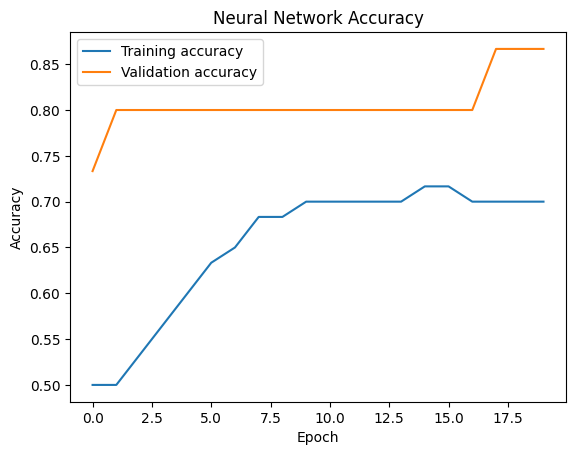

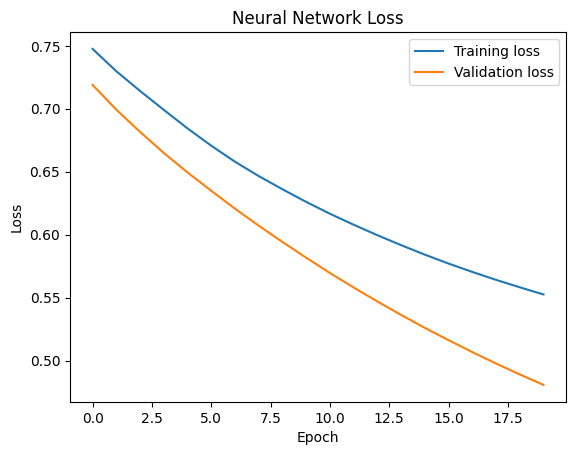

Test accuracy: 60.00%
Test loss: 0.6082


In [7]:
import matplotlib.pyplot as plt

# Training and validation accuracy

plt.plot(
    history.history['accuracy'],
    label='Training accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation accuracy'
)

plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


# Training and validation loss

plt.plot(
    history.history['loss'],
    label='Training loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation loss'
)

plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Test evaluation

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f'Test accuracy: {test_accuracy * 100:.2f}%')
print(f'Test loss: {test_loss:.4f}')

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create three new cyber-activity records

new_records = pd.DataFrame([
    {
        'failed_logins': 0,
        'login_hour': 11,
        'new_device': 0,
        'data_transfer_mb': 35
    },
    {
        'failed_logins': 7,
        'login_hour': 1,
        'new_device': 1,
        'data_transfer_mb': 250
    },
    {
        'failed_logins': 2,
        'login_hour': 23,
        'new_device': 1,
        'data_transfer_mb': 850
    }
])

# Neural Network predictions

new_scaled = scaler.transform(new_records)

probabilities = model.predict(
    new_scaled,
    verbose=0
).flatten()

new_records['nn_probability'] = probabilities.round(3)

new_records['nn_prediction'] = np.where(
    probabilities >= 0.50,
    'Attack',
    'Normal'
)

# Decision Tree model

tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)

tree_accuracy = accuracy_score(y_test, tree_pred)

new_records['tree_prediction'] = np.where(
    tree.predict(new_records[features]) == 1,
    'Attack',
    'Normal'
)

# Display comparison

print(
    f'Neural-network accuracy: {test_accuracy * 100:.2f}%'
)

print(
    f'Decision-tree accuracy: {tree_accuracy * 100:.2f}%'
)

display(new_records)

Neural-network accuracy: 60.00%
Decision-tree accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.125,Normal,Normal
1,7,1,1,250,0.395,Normal,Attack
2,2,23,1,850,0.172,Normal,Attack


In [10]:
# Save results in Excel file

new_records.to_excel(
    'Cyber_Activity_Results.xlsx',
    index=False
)

print("Excel file created successfully!")

Excel file created successfully!
